# Guía 2 · Grupo 20 · Bogotá (versión liviana)

**Gerencia de Proyectos de Analytics · Maestría MIAD** · Fuente: Registro IGAC–SNR 2015–2023 (datos.gov.co, `7y2j-43cv`).

Esta versión trabaja **solo con Bogotá (≈ 665 mil compraventas)** en lugar de todo el país (5,4 millones), así que corre en minutos y cabe en la memoria gratis de Colab. Calcula lo que necesita la Guía 2: completitud del valor, pares de ventas repetidas, segmentos zona × rango de valor, liquidez por zona y rango de valores.

## Cómo usarlo en Colab (4 pasos)

1. Sube este archivo a tu Drive y ábrelo con *Google Colab*.
2. Menú **Entorno de ejecución → Ejecutar todo**. Cuando pida permiso para conectar tu Drive, acepta.
3. Si no encuentra `ipc.csv`, aparece un botón **Elegir archivos**: súbelo (es el mismo archivo del equipo).
4. Espera. La primera vez descarga Bogotá del servidor (≈ 14 consultas, unos minutos) y guarda `compraventas_0125_bogota.csv` en tu carpeta `Guia2_Grupo20`. Las siguientes veces lo lee de ahí.

**Atajo:** si alguien ya tiene `compraventas_0125_bogota.csv`, lo comparte y los demás lo ponen en su carpeta `Guia2_Grupo20`: no hay que descargar nada. Si tienes el archivo del país (`compraventas_0125.csv`) en la carpeta, el notebook saca Bogotá de ahí sin conectarse.

> Esta versión **no incluye** la calidad del dato a nivel nacional (secciones 4). Para eso existe el notebook completo, que tarda mucho más. Los números de las secciones restantes conservan la numeración del completo (5, 6, 7…).

## Mapa

| Sección | Qué hace |
|---|---|
| 1 | Configuración y parámetros |
| 2 | Datos de Bogotá e IPC |
| 3 | Preparación (fechas, llave del predio) |
| 5 | Pares de ventas repetidas y filtros |
| 6 | Valorización real (descuenta el IPC) |
| 7 | Bogotá: completitud, segmentos, liquidez, rango de valores |
| 8 | Cifras clave para la Guía |
| 9 | Cómo cruzar otras fuentes (DANE, Banco de la República) |
| 10 | Pendientes del equipo |

---
## 1. Configuración

Aquí viven **todos los parámetros**. Si el equipo cambia un filtro, se cambia en la celda de parámetros y se vuelve a correr.

> `APP_TOKEN` es opcional: quita el aviso de *throttling* y acelera la descarga. Se pide gratis en datos.gov.co (perfil → Developer Settings).

In [3]:
import os, sys, time, subprocess

def _instalar(*paquetes):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *paquetes], check=False)

for _mod, _pip in [("sodapy", "sodapy"), ("lifelines", "lifelines")]:
    try:
        __import__(_mod)
    except ImportError:
        _instalar(_pip)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

EN_COLAB = "google.colab" in sys.modules
print("Entorno:", "Google Colab" if EN_COLAB else "local / Jupyter")

Entorno: local / Jupyter


In [4]:
# --- Dónde se guardan los archivos ---------------------------------------------
USAR_DRIVE = True                      # en Colab: guarda y lee todo en tu Drive
CARPETA_DRIVE = "Guia2_Grupo20"        # carpeta dentro de "Mi unidad"

if EN_COLAB and USAR_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_DIR = f"/content/drive/MyDrive/{CARPETA_DRIVE}"
else:
    DATA_DIR = "datos"
os.makedirs(DATA_DIR, exist_ok=True)

def ruta(nombre):
    return os.path.join(DATA_DIR, nombre)

print("Carpeta de trabajo:", DATA_DIR)
print("Archivos en la carpeta:", os.listdir(DATA_DIR))

Carpeta de trabajo: datos
Archivos en la carpeta: []


In [5]:
# --- Fuente ---------------------------------------------------------------------
DATASET = "7y2j-43cv"
APP_TOKEN = None                       # opcional: pega aquí tu app token
COD_COMPRAVENTA = 125                  # "0125 COMPRAVENTA" (Resolución 07448/2021 de la SNR)
COLUMNAS = ("pk,matricula,orip,year_radica,fecha_radica_texto,divipola,departamento,"
            "municipio,tipo_predio_zona,categoria_ruralidad_2024,valor")

# --- Alcance --------------------------------------------------------------------
SOLO_BOGOTA = True                     # esta versión trabaja solo con Bogotá
DIVIPOLA_BOGOTA = "11001"
ZONAS = {"50N": "Norte", "50C": "Centro", "50S": "Sur"}   # las tres ORIP de Bogotá

CSV_COMPRAVENTAS = "compraventas_0125_bogota.csv" if SOLO_BOGOTA else "compraventas_0125.csv"

# --- Filtros de calidad de los pares (se justifican en la sección 5) --------------
DIAS_MIN = 30                          # menos de 30 días entre ventas no es una reventa de inversión
VALOR_MIN = 5e6                        # valores menores se consideran poco creíbles como precio
RET_MIN, RET_MAX = 0.2, 5              # retorno total aceptado (0,2x a 5x)
DIAS_ANUALIZAR = 180                   # solo se anualiza si el predio se tuvo 6 meses o más
DIAS_ATIPICO_IDENTICO = 365            # valor idéntico y reventa en este número de días o menos = atípico

# --- Segmentos de Bogotá (sección 7) ---------------------------------------------
N_QUINTILES = 5                        # rangos de valor
N_MIN_SEG = 100                        # pares mínimos para reportar un segmento sin agruparlo (decisión del equipo)
BOOTSTRAP = 1000                       # remuestreos para el intervalo de la mediana

# --- Archivos auxiliares ---------------------------------------------------------
ARCHIVO_IPC = "ipc.csv"                # columnas: fecha, indice (un dato por mes)

---
## 2. Datos

Cada fila del registro es una **anotación registral** (un acto inscrito en un folio), no una venta. Se usan las **compraventas** (`cod_natujur = 125`) de **Bogotá** (`divipola = 11001`, oficinas de registro `50N`, `50C` y `50S`). No se usan `numero_catastral` (vacío) ni `predios_nuevos` (marca solo el 0,36 % de las compraventas de Bogotá; ver 7.6).

### 2.1 Compraventas de Bogotá: lectura o descarga

In [7]:
from sodapy import Socrata
client = Socrata("www.datos.gov.co", APP_TOKEN, timeout=180)

FILTRO = f"cod_natujur={COD_COMPRAVENTA} AND divipola='{DIVIPOLA_BOGOTA}'"

def descargar_compraventas(paso=50_000):
    partes, offset = [], 0
    while True:
        for intento in range(3):
            try:
                r = client.get(DATASET, select=COLUMNAS, where=FILTRO,
                               order="pk", limit=paso, offset=offset)
                break
            except Exception as e:
                print(f"\nreintento {intento + 1}/3:", e)
                time.sleep(10)
        else:
            raise RuntimeError("La descarga falló 3 veces seguidas")
        if not r:
            break
        partes.append(pd.DataFrame.from_records(r))
        offset += paso
        print(f"\r{offset:,} filas descargadas", end="")
    print()
    return pd.concat(partes, ignore_index=True)

archivo_bog = ruta(CSV_COMPRAVENTAS)
archivo_pais = ruta("compraventas_0125.csv")

if os.path.exists(archivo_bog):
    cv_all = pd.read_csv(archivo_bog, dtype=str)
    print(f"Leído de {archivo_bog}: {cv_all.shape[0]:,} filas")
elif os.path.exists(archivo_pais):
    print("Hay archivo del país: se filtra Bogotá (sin conexión)...")
    partes = []
    for trozo in pd.read_csv(archivo_pais, dtype=str, chunksize=500_000):
        partes.append(trozo[trozo["divipola"].str.strip() == DIVIPOLA_BOGOTA])
    cv_all = pd.concat(partes, ignore_index=True)
    cv_all.to_csv(archivo_bog, index=False)
    print(f"Guardado en {archivo_bog}: {cv_all.shape[0]:,} filas")
else:
    print("No hay archivo guardado: se descarga Bogotá del servidor...")
    cv_all = descargar_compraventas()
    cv_all.to_csv(archivo_bog, index=False)
    print(f"Descargado y guardado en {archivo_bog}: {cv_all.shape[0]:,} filas")

No hay archivo guardado: se descarga Bogotá del servidor...
700,000 filas descargadas
Descargado y guardado en datos\compraventas_0125_bogota.csv: 665,086 filas


### 2.2 IPC y cómo subir otros archivos

La función de abajo busca el archivo en la carpeta del equipo; si no está y estás en Colab, abre un botón para subirlo y lo guarda en la carpeta.

> **Sobre el IPC.** El `ipc.csv` del equipo se reconstruyó con la «Inflación total anual» del Banco de la República (índice mensual, base dic-2018 = 100). **No es el índice oficial del DANE.** Para la entrega final conviene reemplazarlo por el oficial con las mismas dos columnas (`fecha`, `indice`).

In [9]:
def asegurar_archivo(nombre, descripcion=""):
    """Devuelve la ruta del archivo; si no existe y estás en Colab, pide subirlo."""
    p = ruta(nombre)
    if os.path.exists(p):
        return p
    if EN_COLAB:
        from google.colab import files
        print(f"Falta '{nombre}' {descripcion}. Súbelo con el botón:")
        subidos = files.upload()
        for n, contenido in subidos.items():
            with open(ruta(n), "wb") as f:
                f.write(contenido)
        if os.path.exists(p):
            return p
    raise FileNotFoundError(f"No se encontró {nombre}. Colócalo en la carpeta {DATA_DIR}.")

try:
    p_ipc = asegurar_archivo(ARCHIVO_IPC, "(columnas: fecha, indice)")
    ipc = pd.read_csv(p_ipc, sep=None, engine="python", encoding="utf-8-sig", decimal=",")
    ipc.columns = [str(c).strip().lower() for c in ipc.columns]
    if not {"fecha", "indice"} <= set(ipc.columns):
        raise ValueError(f"{ARCHIVO_IPC} debe tener las columnas 'fecha' e 'indice'; trae {list(ipc.columns)}")
    ipc["fecha"] = pd.to_datetime(ipc["fecha"])
    ipc["indice"] = pd.to_numeric(ipc["indice"].astype(str).str.replace(",", "."), errors="coerce")
    indice_mensual = ipc.assign(mes=ipc["fecha"].dt.to_period("M")).set_index("mes")["indice"]
    print(f"IPC cargado: {indice_mensual.index.min()} a {indice_mensual.index.max()} ({len(indice_mensual)} meses)")
except Exception as e:
    indice_mensual = None
    print("IPC no disponible, la sección 6 se omite:", e)

IPC no disponible, la sección 6 se omite: No se encontró ipc.csv. Colócalo en la carpeta datos.


---
## 3. Preparación de los datos

Todo llega como texto. Aquí se convierte a tipos útiles y se crea la **llave del predio** (`orip` + `matricula`), que permite encontrar las ventas repetidas.

**Las fechas vienen en tres formatos mezclados.** Si se convierte sin cuidado, `pandas` aprende un solo formato y anula el resto. Se identifican por el largo del texto:

| Largo | Formato | Ejemplo |
|---|---|---|
| 19 | `aaaa-mm-dd 00:00:00` | `2022-04-22 00:00:00` |
| 10 | `dd/mm/aaaa` | `29/01/2019` |
| 8 | `dd/mm/aa` | `20/10/21` |

La conversión se valida comparando el año de la fecha con `year_radica`.

In [11]:
cv = cv_all.copy()
del cv_all

cv["valor"] = pd.to_numeric(cv["valor"], errors="coerce")
cv["year_radica"] = pd.to_numeric(cv["year_radica"], errors="coerce").astype("Int64")

texto_fecha = cv["fecha_radica_texto"].str.strip()
largo = texto_fecha.str.len()
FORMATOS = {19: "%Y-%m-%d %H:%M:%S", 10: "%d/%m/%Y", 8: "%d/%m/%y"}

cv["fecha"] = pd.Series(pd.NaT, index=cv.index, dtype="datetime64[ns]")
for n_car, formato in FORMATOS.items():
    m = largo == n_car
    cv.loc[m, "fecha"] = pd.to_datetime(texto_fecha[m], format=formato, errors="coerce")

print("Formatos de fecha encontrados (largo del texto):")
display(largo.value_counts().rename("filas").to_frame())
print(f"Fechas sin convertir:                   {cv['fecha'].isna().mean():.2%}")
print(f"Año de la fecha distinto a year_radica: {(cv['fecha'].dt.year != cv['year_radica']).mean():.2%}")

# Llave del predio como número entero (ahorra memoria) y bandera de valor válido
cv["orip"] = cv["orip"].str.strip()
cv["predio"] = pd.factorize(cv["orip"] + "-" + cv["matricula"].str.strip())[0]
cv["valor_valido"] = cv["valor"] > 0

for c in ["orip", "divipola", "departamento", "municipio", "tipo_predio_zona", "categoria_ruralidad_2024"]:
    cv[c] = cv[c].astype("category")

cvv = cv[cv["valor_valido"]].copy()
print(f"\nCompraventas: {len(cv):,}  |  con valor válido: {len(cvv):,}")

Formatos de fecha encontrados (largo del texto):


,filas
fecha_radica_texto,
19,665082
8,4


Fechas sin convertir:                   0.00%
Año de la fecha distinto a year_radica: 0.00%

Compraventas: 665,086  |  con valor válido: 262,796


---
## 5. Ventas repetidas: pares de compraventas del mismo predio

La misma matrícula puede venderse más de una vez. Cada compraventa se empareja con la **anterior del mismo predio**; de cada par salen el retorno, el tiempo entre ventas (proxy de liquidez) y, al deflactar, la valorización **real**.

### 5.1 ¿Cuántos predios se vendieron más de una vez?

In [13]:
cvv = cvv.dropna(subset=["fecha"]).sort_values(["predio", "fecha", "pk"]).copy()

ventas_por_predio = cvv.groupby("predio").size()
print(f"Predios con al menos una compraventa con valor: {len(ventas_por_predio):,}")
print(f"Con dos o más compraventas:                     {(ventas_por_predio >= 2).sum():,} ({(ventas_por_predio >= 2).mean():.1%})")
display(ventas_por_predio.value_counts().sort_index().head(6).rename("predios").to_frame())

Predios con al menos una compraventa con valor: 252,406
Con dos o más compraventas:                     9,894 (3.9%)


,predios
1,242512
2,9493
3,367
4,20
5,5
6,1


### 5.2 Construcción de los pares

In [15]:
grupo = cvv.groupby("predio")
cvv["valor_ant"] = grupo["valor"].shift()
cvv["fecha_ant"] = grupo["fecha"].shift()

pares = cvv.dropna(subset=["valor_ant"]).copy()
pares["dias"] = (pares["fecha"] - pares["fecha_ant"]).dt.days
pares["ret_total"] = pares["valor"] / pares["valor_ant"]

print(f"Compraventas con valor: {len(cvv):,}  |  pares: {len(pares):,}")
print("\nDías entre ventas:")
print(pares["dias"].describe(percentiles=[.05, .25, .5, .75, .95]).round(0))
print(f"\nPares con 0 días: {(pares['dias'] == 0).mean():.2%}")
print("\nRetorno total (valor / valor anterior), sin filtrar:")
print(pares["ret_total"].describe(percentiles=[.01, .05, .5, .95, .99]))

Compraventas con valor: 262,796  |  pares: 10,390

Días entre ventas:
count    10390.0
mean       288.0
std        205.0
min          0.0
5%          44.0
25%        126.0
50%        233.0
75%        416.0
95%        706.0
max        938.0
Name: dias, dtype: float64

Pares con 0 días: 2.01%

Retorno total (valor / valor anterior), sin filtrar:
count    10390.000000
mean         6.913991
std        162.212606
min          0.000100
1%           0.073168
5%           0.722222
50%          1.157895
95%          3.159034
99%         41.517917
max      11900.000000
Name: ret_total, dtype: float64


### 5.4 Filtros de calidad (el «embudo»)

In [17]:
pasos = [("pares totales", len(pares))]
pf = pares[pares["dias"] >= DIAS_MIN]
pasos.append((f"días entre ventas >= {DIAS_MIN}", len(pf)))
pf = pf[(pf["valor_ant"] >= VALOR_MIN) & (pf["valor"] >= VALOR_MIN)]
pasos.append((f"ambos valores >= {VALOR_MIN:,.0f}", len(pf)))
pf = pf[pf["ret_total"].between(RET_MIN, RET_MAX)]
pasos.append((f"retorno entre {RET_MIN}x y {RET_MAX}x", len(pf)))

embudo = pd.DataFrame(pasos, columns=["filtro", "pares"])
embudo["pct_del_total"] = (embudo["pares"] / embudo["pares"].iloc[0]).round(3)
display(embudo)

,filtro,pares,pct_del_total
0,pares totales,10390,1.000
1,días entre ventas >= 30,10036,0.966
2,"ambos valores >= 5,000,000",9800,0.943
3,retorno entre 0.2x y 5x,9332,0.898


### 5.5 Retorno nominal anualizado

Solo se anualiza si el predio se tuvo `DIAS_ANUALIZAR` días o más; con menos tiempo, anualizar infla el resultado. Se usa la **mediana** porque el promedio lo jalan unos pocos extremos.

In [19]:
pa = pf[pf["dias"] >= DIAS_ANUALIZAR].copy()
pa["ret_anual"] = pa["ret_total"] ** (365.25 / pa["dias"]) - 1
print(f"Pares para anualizar: {len(pa):,}")
print(pa["ret_anual"].describe(percentiles=[.05, .25, .5, .75, .95]))

Pares para anualizar: 5,990
count    5990.000000
mean        0.265173
std         0.570455
min        -0.946974
5%         -0.169477
25%         0.022450
50%         0.127636
75%         0.367675
95%         0.989955
max        17.566552
Name: ret_anual, dtype: float64


### 5.6 Pares con valor idéntico y 5.7 criterio para excluir operaciones atípicas

Un valor idéntico en dos ventas no es un error por sí mismo (valores redondos o simbólicos son comunes). La señal de atipicidad es la **combinación** de valor idéntico y reventa muy rápida. **Criterio adoptado:** se excluyen del cálculo principal los pares con valor idéntico y `DIAS_ATIPICO_IDENTICO` días o menos entre ventas. Es una decisión de criterio, no un corte que el dato imponga; por eso se reporta también la cifra con todos los pares y con otros umbrales.

Pares con valor idéntico (cualquier plazo): 432 (7.2%)
Pares atípicos (idéntico y <= 365 días): 252 (4.2%)
Pares en el cálculo principal: 5,738
Mediana nominal anualizada, todos los pares:   12.76%
Mediana nominal anualizada, cálculo principal: 13.88%


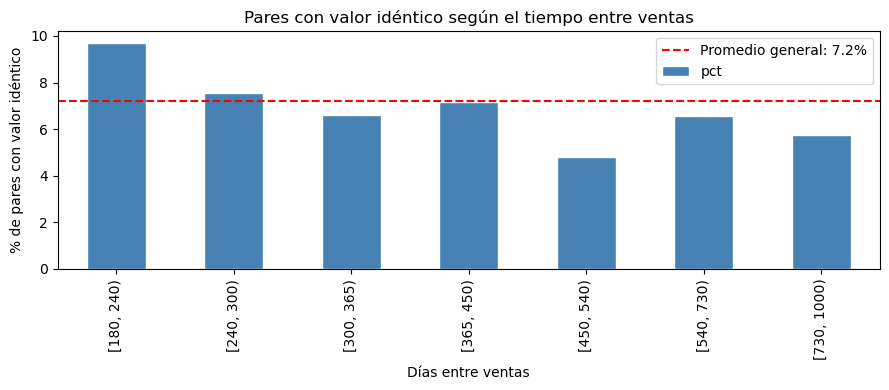

In [21]:
pa["valor_identico"] = pa["valor"] == pa["valor_ant"]
pa["atipico_identico"] = pa["valor_identico"] & (pa["dias"] <= DIAS_ATIPICO_IDENTICO)
pa_principal = pa[~pa["atipico_identico"]]

print(f"Pares con valor idéntico (cualquier plazo): {pa['valor_identico'].sum():,} ({pa['valor_identico'].mean():.1%})")
print(f"Pares atípicos (idéntico y <= {DIAS_ATIPICO_IDENTICO} días): {pa['atipico_identico'].sum():,} ({pa['atipico_identico'].mean():.1%})")
print(f"Pares en el cálculo principal: {len(pa_principal):,}")
print(f"Mediana nominal anualizada, todos los pares:   {pa['ret_anual'].median():.2%}")
print(f"Mediana nominal anualizada, cálculo principal: {pa_principal['ret_anual'].median():.2%}")

cortes = [180, 240, 300, 365, 450, 540, 730, 1000, 1500, 4000]
tramos = (pa.assign(tramo=pd.cut(pa["dias"], bins=cortes, right=False))
            .groupby("tramo", observed=True)["valor_identico"].agg(pct="mean", n="size"))
tramos["pct"] *= 100
ax = tramos["pct"].plot(kind="bar", figsize=(9, 4), color="steelblue", edgecolor="white")
ax.axhline(pa["valor_identico"].mean() * 100, color="red", linestyle="--",
           label=f"Promedio general: {pa['valor_identico'].mean():.1%}")
ax.set_xlabel("Días entre ventas"); ax.set_ylabel("% de pares con valor idéntico")
ax.set_title("Pares con valor idéntico según el tiempo entre ventas"); ax.legend()
plt.tight_layout(); plt.show()

---
## 6. Valorización real: descontar la inflación

El retorno nominal no dice si el inversionista ganó o perdió poder adquisitivo. Se divide cada valor por el IPC de su mes: `ret_real = (valor / IPC) / (valor_ant / IPC_ant)`.

In [23]:
pr, pr_todos = None, None
if indice_mensual is None:
    print("Sin IPC: se omite esta sección (todo lo anterior sigue valiendo, en términos nominales).")
else:
    pa["mes"] = pa["fecha"].dt.to_period("M")
    pa["mes_ant"] = pa["fecha_ant"].dt.to_period("M")
    pa["ipc"] = pa["mes"].map(indice_mensual)
    pa["ipc_ant"] = pa["mes_ant"].map(indice_mensual)

    pr_todos = pa.dropna(subset=["ipc", "ipc_ant"]).copy()
    print(f"Pares sin IPC (fuera del rango de la serie): {len(pa) - len(pr_todos):,}")
    pr_todos["ret_real"] = (pr_todos["valor"] / pr_todos["ipc"]) / (pr_todos["valor_ant"] / pr_todos["ipc_ant"])
    pr_todos["ret_real_anual"] = pr_todos["ret_real"] ** (365.25 / pr_todos["dias"]) - 1
    pr = pr_todos[~pr_todos["atipico_identico"]].copy()

    print(f"\nRetorno REAL anualizado (cálculo principal, sin atípicos):")
    print(pr["ret_real_anual"].describe(percentiles=[.05, .25, .5, .75, .95]))
    print(f"\nMediana nominal (principal): {pr['ret_anual'].median():.2%}  |  mediana real (principal): {pr['ret_real_anual'].median():.2%}")
    print(f"Mediana real con TODOS los pares (sensibilidad):        {pr_todos['ret_real_anual'].median():.2%}")
    print(f"Mediana real sin NINGÚN par idéntico (cota superior):   {pr_todos.loc[~pr_todos['valor_identico'], 'ret_real_anual'].median():.2%}")
    print(f"Pares con retorno real negativo (principal):            {(pr['ret_real_anual'] < 0).mean():.1%}")

Sin IPC: se omite esta sección (todo lo anterior sigue valiendo, en términos nominales).


In [24]:
if pr is not None:
    print("Por categoría de ruralidad (cálculo principal):")
    display(pr.groupby("categoria_ruralidad_2024", observed=True)["ret_real_anual"]
              .agg(mediana="median", n="size").query("n >= 500"))
    print("\nPor año de la segunda venta: cálculo principal frente a todos los pares")
    display(pd.DataFrame({
        "mediana_principal": pr.groupby("year_radica")["ret_real_anual"].median(),
        "n_principal": pr.groupby("year_radica").size(),
        "mediana_todos": pr_todos.groupby("year_radica")["ret_real_anual"].median(),
        "n_todos": pr_todos.groupby("year_radica").size()}))
    print("\nSensibilidad al umbral de operaciones atípicas:")
    for umbral in [300, 365, 450]:
        atip = pr_todos["valor_identico"] & (pr_todos["dias"] <= umbral)
        print(f"  {umbral} días: atípicos {atip.sum():,} ({atip.mean():.1%}) | "
              f"mediana real {pr_todos.loc[~atip, 'ret_real_anual'].median():.2%}")

---
## 7. Bogotá: territorio de estudio

Esta sección responde a las dos decisiones del inversionista: **(1)** en qué zonas y rangos de valor concentrar la búsqueda y **(2)** si el precio de una oferta está en el rango esperado.

> **Aviso de método.** El registro no trae barrio, localidad, área, estrato ni tipo de inmueble. Por eso los segmentos son **zona registral (ORIP 50N, 50C, 50S) × rango de valor**. La variable `predios_nuevos` no permite separar vivienda nueva de usada (ver 7.6).

### 7.1 Volumen y completitud del valor en Bogotá

In [26]:
bog = cv[cv["divipola"].astype(str) == DIVIPOLA_BOGOTA].copy()
print(f"Compraventas en Bogotá: {len(bog):,}  |  con valor: {bog['valor_valido'].mean():.1%}")

comp_bog = bog.groupby("year_radica").agg(total=("pk", "size"), con_valor=("valor_valido", "sum"),
                                          pct_con_valor=("valor_valido", "mean")).round(3)
display(comp_bog)

print("\nCompraventas por ORIP (las tres zonas de Bogotá):")
display(bog["orip"].astype(str).value_counts().loc[lambda s: s.index.isin(ZONAS)].rename("compraventas").to_frame())

Compraventas en Bogotá: 665,086  |  con valor: 39.5%


,total,con_valor,pct_con_valor
year_radica,,,
2015,60357,0,0.000
2016,77851,0,0.000
2017,52990,0,0.000
2018,50572,0,0.000
2019,62777,0,0.000
2020,61452,0,0.000
2021,102107,67299,0.659
2022,102164,101424,0.993
2023,94816,94073,0.992



Compraventas por ORIP (las tres zonas de Bogotá):


,compraventas
orip,
50N,238279
50C,235378
50S,191420


> **Para leerlo.** Si el valor de Bogotá no aparece antes de 2021, los pares **con valor** (valorización real) solo cubren 2021–2023, y la validación temporal de la valorización es muy corta. La **liquidez** no necesita el valor y puede usar los nueve años (7.5).

### 7.2 Pares de Bogotá: con valor y sin exigir valor

In [28]:
pb = pr[pr["divipola"].astype(str) == DIVIPOLA_BOGOTA].copy() if pr is not None else None
if pb is not None:
    print(f"Pares con valor (cálculo principal): {len(pb):,}")
    display(pb.groupby("year_radica").size().rename("pares_con_valor").to_frame())

b = (bog.dropna(subset=["fecha"]).sort_values(["predio", "fecha", "pk"])
        [["predio", "fecha", "orip", "year_radica", "pk"]].copy())
b["fecha_ant"] = b.groupby("predio")["fecha"].shift()
pares_bog_todos = b.dropna(subset=["fecha_ant"]).copy()
pares_bog_todos["dias"] = (pares_bog_todos["fecha"] - pares_bog_todos["fecha_ant"]).dt.days
print(f"\nPares sin exigir valor: {len(pares_bog_todos):,}")
display(pares_bog_todos.groupby("year_radica").size().rename("pares_sin_exigir_valor").to_frame())
print(f"Mediana de días entre ventas (todos): {pares_bog_todos['dias'].median():.0f}"
      + (f"  |  (con valor): {pb['dias'].median():.0f}" if pb is not None and len(pb) else ""))


Pares sin exigir valor: 73,120


,pares_sin_exigir_valor
year_radica,
2015,1307
2016,3867
2017,4118
2018,4852
2019,7138
2020,7906
2021,13666
2022,15393
2023,14873


Mediana de días entre ventas (todos): 811


> **Cuidado al comparar los días.** La mediana con valor sale más corta porque un par con valor en *ambas* ventas no puede durar más de lo que dura el periodo con valor (2021–2023). Es un sesgo de selección, no una diferencia real de liquidez. Para liquidez se usan todos los pares y análisis de supervivencia (7.5).

### 7.3 Segmentos: zona registral × rango de valor (valorización real)

El rango de valor se define con **quintiles del valor de la primera venta** del par. Para cada segmento se reporta el n, la mediana del retorno real anualizado y un **intervalo del 90 % por bootstrap**.

In [30]:
rng = np.random.default_rng(42)

def ic_mediana(x, B=BOOTSTRAP, nivel=0.90):
    x = np.asarray(x, dtype=float)
    if len(x) < 2:
        return (np.nan, np.nan)
    idx = rng.integers(0, len(x), size=(B, len(x)))
    meds = np.median(x[idx], axis=1)
    a = (1 - nivel) / 2
    lo, hi = np.quantile(meds, [a, 1 - a])
    return (lo, hi)

seg = None
if pb is not None and len(pb) > 0:
    pb["zona"] = pb["orip"].astype(str).map(ZONAS)
    pb = pb.dropna(subset=["zona"]).copy()
    pb["q"] = pd.qcut(pb["valor_ant"], N_QUINTILES, labels=False, duplicates="drop") + 1

    print("Pares por zona y rango de valor (1 = más bajo):")
    display(pb.groupby(["zona", "q"], observed=True).size().unstack(fill_value=0))

    filas = []
    for (z, q), g in pb.groupby(["zona", "q"], observed=True):
        lo, hi = ic_mediana(g["ret_real_anual"].values)
        filas.append({"zona": z, "rango_valor": int(q), "n": len(g),
                      "mediana_real": g["ret_real_anual"].median(), "ic90_inf": lo, "ic90_sup": hi})
    seg = pd.DataFrame(filas)
    seg["ancho_ic_pp"] = (seg["ic90_sup"] - seg["ic90_inf"]) * 100
    seg["n_suficiente"] = seg["n"] >= N_MIN_SEG
    display(seg.round(4))
    print(f"Segmentos con n >= {N_MIN_SEG}: {seg['n_suficiente'].sum()} de {len(seg)}  |  "
          f"ancho mediano del intervalo: {seg['ancho_ic_pp'].median():.1f} p.p.")
else:
    print("No hay pares con valor para Bogotá (¿falta el IPC o el periodo no tiene valor?).")

No hay pares con valor para Bogotá (¿falta el IPC o el periodo no tiene valor?).


> **Para decidir en equipo.** Con intervalos tan anchos, la meta «intervalo del 90 % menor a 3 p.p.» probablemente no se cumple. Opciones: (a) reportar siempre el intervalo y el n, (b) fijar un ancho máximo realista y **agrupar** los segmentos que no lo alcancen, (c) usar menos rangos de valor (terciles).

### 7.4 Los segmentos más pequeños

In [32]:
if seg is not None:
    display(seg.sort_values("n").head(5).round(4))

### 7.5 Liquidez por zona: análisis de supervivencia (usa todos los años, no necesita el valor)

Para cada compraventa se mide cuánto tarda el predio en volver a venderse. Los predios que **aún no se han revendido** al final de la serie no se descartan: se tratan como **censurados** (Kaplan-Meier). Así no se subestima el tiempo de reventa. La probabilidad de reventa a *t* años es `1 − S(t)`.

Compraventas en el análisis de liquidez: 663,279  |  con reventa observada: 10.8%


,P(reventa ≤ 1 años),P(reventa ≤ 3 años),P(reventa ≤ 5 años),n
Centro,0.034,0.091,0.145,234581
Norte,0.028,0.077,0.136,237793
Sur,0.033,0.076,0.120,190905


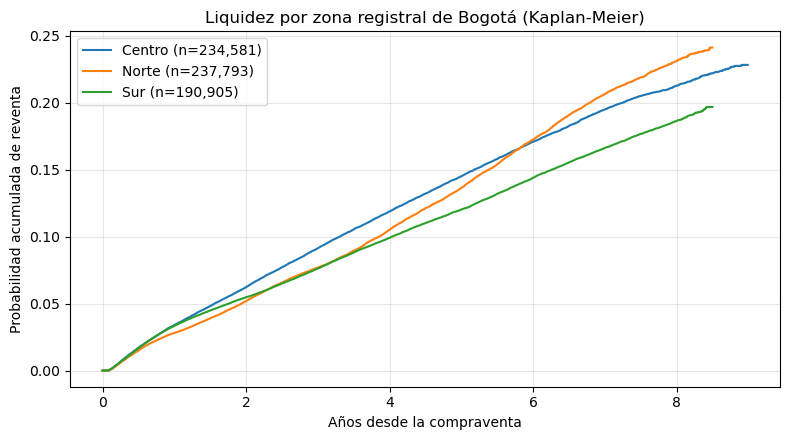

In [34]:
from lifelines import KaplanMeierFitter

FECHA_FIN = cv["fecha"].max()
liq = b.copy()
liq["fecha_sig"] = liq.groupby("predio")["fecha"].shift(-1)
liq["evento"] = liq["fecha_sig"].notna()
liq["dur"] = (liq["fecha_sig"].fillna(FECHA_FIN) - liq["fecha"]).dt.days
liq = liq[~(liq["evento"] & (liq["dur"] < DIAS_MIN))]      # no son reventas de inversión
liq = liq[liq["dur"] > 0].copy()
liq["zona"] = liq["orip"].astype(str).map(ZONAS)
liq = liq.dropna(subset=["zona"])
print(f"Compraventas en el análisis de liquidez: {len(liq):,}  |  con reventa observada: {liq['evento'].mean():.1%}")

def prob_reventa(d, dias):
    if len(d) < 30:
        return np.nan
    k = KaplanMeierFitter().fit(d["dur"], d["evento"])
    return 1 - float(k.predict(dias))

tabla_liq = pd.DataFrame({
    f"P(reventa ≤ {a} años)": {z: prob_reventa(g, int(365.25 * a)) for z, g in liq.groupby("zona")}
    for a in (1, 3, 5)})
tabla_liq["n"] = liq.groupby("zona").size()
display(tabla_liq.round(3))

fig, ax = plt.subplots(figsize=(8, 4.5))
for z, g in liq.groupby("zona"):
    k = KaplanMeierFitter().fit(g["dur"] / 365.25, g["evento"], label=f"{z} (n={len(g):,})")
    ((1 - k.survival_function_)).plot(ax=ax)
ax.set_xlabel("Años desde la compraventa"); ax.set_ylabel("Probabilidad acumulada de reventa")
ax.set_title("Liquidez por zona registral de Bogotá (Kaplan-Meier)"); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

**Validación temporal de la liquidez (diseño de la validación retrospectiva).** Se compara si el orden de las zonas, calculado con compraventas de **2015–2017**, se mantiene con las de **2018–2020**. Si el orden se conserva, la liquidez pasada anticipa la futura; si cambia, la métrica no es estable.

In [36]:
liq["cohorte"] = np.where(liq["year_radica"] <= 2017, "2015-2017",
                  np.where(liq["year_radica"] <= 2020, "2018-2020", "2021-2023"))
val_temporal = pd.DataFrame({
    c: {z: prob_reventa(g, int(365.25 * 3)) for z, g in liq[liq["cohorte"] == c].groupby("zona")}
    for c in ["2015-2017", "2018-2020"]})
val_temporal.columns = [f"P(reventa ≤ 3 años), compras {c}" for c in val_temporal.columns]
display(val_temporal.round(3))
if val_temporal.notna().all().all():
    o1 = list(val_temporal.iloc[:, 0].sort_values(ascending=False).index)
    o2 = list(val_temporal.iloc[:, 1].sort_values(ascending=False).index)
    print("Orden de zonas (más a menos líquida):", o1, "→", o2, "| se conserva" if o1 == o2 else "| CAMBIA")

,"P(reventa ≤ 3 años), compras 2015-2017","P(reventa ≤ 3 años), compras 2018-2020"
Centro,0.111,0.088
Norte,0.058,0.086
Sur,0.064,0.080


Orden de zonas (más a menos líquida): ['Centro', 'Sur', 'Norte'] → ['Centro', 'Norte', 'Sur'] | CAMBIA


### 7.6 ¿Sirve `predios_nuevos` para separar vivienda nueva de usada?

Esta celda consulta al servidor cuántas compraventas de Bogotá tienen la marca. (Resultado de referencia del equipo: vale 1 en 2.395 de 665.086 compraventas, 0,36 %, así que **no sirve** como proxy de vivienda nueva.)

In [38]:
try:
    r = client.get(DATASET, select="year_radica, predios_nuevos, count(*) as n",
                   where=f"cod_natujur={COD_COMPRAVENTA} AND divipola='{DIVIPOLA_BOGOTA}'",
                   group="year_radica, predios_nuevos", order="year_radica", limit=1000)
    pn = pd.DataFrame.from_records(r)
    pn["n"] = pn["n"].astype(int)
    tab = pn.pivot_table(index="year_radica", columns="predios_nuevos", values="n", aggfunc="sum", fill_value=0)
    tab["pct_marcadas"] = (tab.get("1", 0) / tab.sum(axis=1) * 100).round(2)
    display(tab)
    print(f"Marcadas con 1 en todo el periodo: {tab.get('1', pd.Series([0])).sum():,} de {tab.drop(columns='pct_marcadas').sum().sum():,}")
except Exception as e:
    print("Consulta omitida (sin conexión o columna no disponible):", e)

predios_nuevos,0,1,pct_marcadas
year_radica,,,
2015,59824,533,0.88
2016,77375,476,0.61
2017,52917,73,0.14
2018,50419,153,0.30
2019,62715,62,0.10
2020,61389,63,0.10
2021,101799,308,0.30
2022,101785,379,0.37
2023,94468,348,0.37


Marcadas con 1 en todo el periodo: 2,395 de 665,086


### 7.7 Rango esperado del valor por zona (decisión 2)

Referencia para saber si el precio de una oferta está dentro de lo que históricamente se registró. Los valores se llevan a **pesos del último mes del IPC** para poder compararlos entre años.

> **Ojo con la definición del segmento.** Si el segmento incluye el *rango de valor*, la pregunta «¿este precio está en rango?» se vuelve circular (el rango ya se definió con el precio). Para la decisión 2 el segmento debe usar variables **ajenas al precio** (aquí, solo la zona registral y el año). Es un punto a decidir en el equipo.

In [40]:
if indice_mensual is not None:
    ref = indice_mensual.dropna().iloc[-1]
    bv = bog[bog["valor_valido"] & bog["fecha"].notna()].copy()
    bv["mes"] = bv["fecha"].dt.to_period("M")
    bv["ipc"] = bv["mes"].map(indice_mensual)
    bv = bv.dropna(subset=["ipc"])
    bv["valor_real"] = bv["valor"] * ref / bv["ipc"]
    bv["zona"] = bv["orip"].astype(str).map(ZONAS)
    bv = bv.dropna(subset=["zona"])
    bv = bv[bv["valor"] >= VALOR_MIN]
    rango = (bv.groupby(["zona", "year_radica"])["valor_real"]
               .quantile([.10, .50, .90]).unstack().rename(columns={.10: "p10", .50: "mediana", .90: "p90"}))
    rango["n"] = bv.groupby(["zona", "year_radica"]).size()
    print(f"Compraventas de Bogotá con valor (>= {VALOR_MIN:,.0f}): {len(bv):,}")
    print("Valores en pesos constantes del último mes del IPC:")
    display((rango / [1e6, 1e6, 1e6, 1]).round(1).rename(columns={"p10": "p10 (M$)", "mediana": "mediana (M$)", "p90": "p90 (M$)"}))
else:
    print("Sin IPC: se omite el rango en pesos constantes.")

Sin IPC: se omite el rango en pesos constantes.


---
## 8. Cifras clave para la Guía

Una sola tabla con las cifras que aparecen en el documento, para que **la Guía y el notebook digan lo mismo**. Si una cifra cambia al correr con datos nuevos, hay que actualizar el texto.

In [42]:
def v(f, default="n.d."):
    try:
        return f()
    except Exception:
        return default

filas = [
    ("Compraventas totales (cod. 0125)", v(lambda: f"{len(cv):,}")),
    ("Compraventas sin valor", v(lambda: f"{1 - cv['valor_valido'].mean():.1%}")),
    ("Compraventas con valor", v(lambda: f"{len(cvv):,}")),
    ("Predios con 2 o más compraventas con valor", v(lambda: f"{(ventas_por_predio >= 2).sum():,} ({(ventas_por_predio >= 2).mean():.1%})")),
    ("Pares de ventas repetidas (con valor)", v(lambda: f"{len(pares):,}")),
    ("Pares tras filtros de calidad", v(lambda: f"{len(pf):,} ({len(pf) / len(pares):.1%})")),
    ("Pares usados para anualizar", v(lambda: f"{len(pa):,}")),
    ("Mediana de días entre ventas (con valor, sin filtrar)", v(lambda: f"{pares['dias'].median():,.0f}")),
    ("Retorno nominal anualizado, mediana", v(lambda: f"{pa['ret_anual'].median():.1%}")),
    ("Pares atípicos (valor idéntico y reventa ≤ 365 días)", v(lambda: f"{pa['atipico_identico'].sum():,} ({pa['atipico_identico'].mean():.1%})")),
    ("Retorno real anualizado, mediana (principal)", v(lambda: f"{pr['ret_real_anual'].median():.1%}")),
    ("Retorno real anualizado, mediana (todos los pares)", v(lambda: f"{pr_todos['ret_real_anual'].median():.1%}")),
    ("Bogotá: compraventas", v(lambda: f"{len(bog):,}")),
    ("Bogotá: % con valor", v(lambda: f"{bog['valor_valido'].mean():.1%}")),
    ("Bogotá: pares con valor (principal)", v(lambda: f"{len(pb):,}")),
    ("Bogotá: pares sin exigir valor", v(lambda: f"{len(pares_bog_todos):,}")),
    ("Bogotá: segmentos zona × rango con n suficiente", v(lambda: f"{int(seg['n_suficiente'].sum())} de {len(seg)}")),
    ("Bogotá: ancho mediano del intervalo 90 % (p.p.)", v(lambda: f"{seg['ancho_ic_pp'].median():.1f}")),
]
display(pd.DataFrame(filas, columns=["cifra", "valor en el notebook"]))

,cifra,valor en el notebook
0,Compraventas totales (cod. 0125),"665,086"
1,Compraventas sin valor,60.5%
2,Compraventas con valor,"262,796"
3,Predios con 2 o más compraventas con valor,"9,894 (3.9%)"
4,Pares de ventas repetidas (con valor),"10,390"
5,Pares tras filtros de calidad,"9,332 (89.8%)"
6,Pares usados para anualizar,"5,990"
7,"Mediana de días entre ventas (con valor, sin f...",233
8,"Retorno nominal anualizado, mediana",12.8%
9,Pares atípicos (valor idéntico y reventa ≤ 365...,252 (4.2%)


---
## 9. Cómo relacionar otras fuentes (DANE y Banco de la República)

**Sí: en Colab puedes subir los demás archivos y cruzarlos con las compraventas.** Dos formas:

1. **Botón de subir** (`asegurar_archivo`, sección 2.3): el archivo queda en la carpeta del equipo en Drive.
2. **Subirlos directo a la carpeta `Guia2_Grupo20` de Drive** desde el navegador; el notebook los lee desde ahí.

> Los archivos subidos *sin* Drive se borran cuando Colab se desconecta. Con Drive montado quedan guardados.

**Cómo se cruzan.** Cada fuente se lleva a una **serie por mes** (o por año) y se une a los pares por el mes de la venta:

| Fuente | Nivel | Llave para cruzar |
|---|---|---|
| Tasas hipotecarias (Banco de la República) | Nacional, mensual | `mes` de la segunda venta |
| Licencias de construcción (DANE) | Municipal, mensual o anual | `divipola` + `mes` (o año) |
| Población y vivienda (DANE) | Municipal, anual | `divipola` + `year_radica` |
| IPC | Nacional, mensual | `mes` (ya se usa en la sección 6) |

La función `cargar_serie` lee un CSV con una columna de fecha y otra de valor; `unir_serie` la pega a cualquier tabla que tenga una columna `mes` de tipo período mensual.

In [44]:
def cargar_serie(nombre_archivo, col_fecha, col_valor, nuevo_nombre):
    """Lee un CSV (fecha + valor) y devuelve una Serie indexada por mes (Period M)."""
    p = asegurar_archivo(nombre_archivo, f"(columnas: {col_fecha}, {col_valor})")
    df = pd.read_csv(p, sep=None, engine="python", encoding="utf-8-sig", decimal=",")
    df.columns = [str(c).strip() for c in df.columns]
    df[col_fecha] = pd.to_datetime(df[col_fecha])
    df[col_valor] = pd.to_numeric(df[col_valor].astype(str).str.replace(",", "."), errors="coerce")
    return (df.assign(mes=df[col_fecha].dt.to_period("M")).groupby("mes")[col_valor].mean()
              .rename(nuevo_nombre))

def unir_serie(tabla, serie, columna_mes="mes"):
    """Pega una serie mensual a una tabla que tenga una columna de período mensual."""
    return tabla.join(serie, on=columna_mes)

# --- Ejemplo (descomenta cuando tengas el archivo; ajusta los nombres de columnas) ---
# tasas = cargar_serie("tasas_hipotecarias.csv", "fecha", "tasa", "tasa_hipotecaria")
# pb = unir_serie(pb.assign(mes=pb["fecha"].dt.to_period("M")), tasas)
# display(pb.groupby("year_radica")[["ret_real_anual", "tasa_hipotecaria"]].median())
print("Funciones listas: cargar_serie(...) y unir_serie(...)")

Funciones listas: cargar_serie(...) y unir_serie(...)


---
## 10. Pendientes y decisiones del equipo

- [ ] **Territorio:** confirmar si se mantiene Bogotá (liquidez 2015–2023; valorización 2021–2023) o se cambia a ciudades con nueve años de valor.
- [ ] **Segmentos:** aprobar zona × rango de valor y el criterio para agrupar los segmentos con n pequeño (`N_MIN_SEG`).
- [ ] **Metas de intervalo:** reemplazar «intervalo < 3 p.p.» por una meta realista con los anchos de 7.3.
- [ ] **IPC oficial:** reemplazar `ipc.csv` por el índice oficial del DANE.
- [ ] **Umbrales de los filtros:** justificar `DIAS_MIN`, `VALOR_MIN`, `RET_MIN/RET_MAX` y `DIAS_ANUALIZAR` y mostrar el embudo en el informe.
- [ ] **Decisión 2 (rango de precios):** definir el segmento sin usar el rango de valor, para que no sea circular.
- [ ] **Contexto económico:** descargar tasas y licencias de construcción y cruzarlas (sección 9).
- [ ] **Fiducia (0164) y leasing (0168):** estudiar si sirven como proxy de vivienda nueva.